# A 12-site Hofstadter–Hubbard model with coupled wires

This is a small **CPU** example using Quantax's complex multiplicative Pfaffian backflow ansatz. We use three periodic wires of four sites, half filling $(N_\uparrow,N_\downarrow)=(6,6)$, and the **same orbital flux for both spins**. The default short optimization illustrates the workflow; it is not a converged ground-state result.

**Install once in your notebook environment**, then select that environment's Python kernel:
```bash
python -m pip install "quantax[full] @ git+https://github.com/chrisrothUT/quantax.git@multbackflowpfaffian" matplotlib nbformat ipykernel
```
This requires a compatible Python/JAX environment (Python 3.11–3.13). No CUDA installation or cluster allocation is needed. The first JAX compilation can dominate the small run. If JAX has already been imported, restart the kernel before running this notebook. Rerun the whole notebook from a fresh kernel when changing the lattice or particle sector, because Quantax stores the lattice globally.

Background: [Divić et al., triangular-lattice Hofstadter–Hubbard model](https://arxiv.org/abs/2406.15348). The explicit anisotropic gauge and checks below define this example independently of a paper's gauge convention.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"  # Set before importing JAX.
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")

import time
from math import comb
import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
import quantax as qtx
from quantax.operator import (Operator, create_u, create_d,
                             annihilate_u, annihilate_d, number_u, number_d)

jax.config.update("jax_enable_x64", True)
jax.config.update("jax_default_matmul_precision", "highest")
qtx.set_default_dtype(jnp.complex128)
qtx.set_random_seed(42)
assert all(d.platform == "cpu" for d in jax.devices())
assert hasattr(qtx.model, "MultiplicativePfBackflow"), "Install the multbackflowpfaffian branch."
print("Quantax:", qtx.__file__)
print("Devices:", jax.devices())

/mnt/home/croth/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-g32n67v4 because there was an issue with the default path (/mnt/home/croth/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Quantax: /tmp/quantax-multbackflow-publish/quantax/__init__.py
Devices: [CpuDevice(id=0)]


## Parameters and geometry

Set $t_\parallel=1$ as the energy unit. The horizontal direction $\mathbf a_1=(1,0)$ runs along each wire. Both interwire directions, $\mathbf a_2=(1/2,\sqrt3/2)$ and $\mathbf a_2-\mathbf a_1$, have amplitude $t_\perp$. Thus $t_\perp=0$ gives decoupled Hubbard chains, and $t_\perp=t_\parallel$ gives isotropic hopping magnitudes. Here `U=7` is an editable example, as are `tpar` and `tperp`.

We use a torus (periodic along and between wires). A gauge with period two along a wire is represented as a **two-site unit cell**: cell vectors $2\mathbf a_1,\mathbf a_2$, with offsets $0,\mathbf a_1$. `Lx` must be even for this gauge on the torus.

In [2]:
Lx, Ly = 4, 3
Nup, Ndown = 6, 6
tpar, tperp, U = 1.0, 0.5, 7.0
nsteps, nsamples = 30, 64
n_eval_blocks = 20
C0 = 0.1
assert Lx >= 4 and Lx % 2 == 0 and Ly >= 3
assert tpar > 0 and tperp >= 0 and U >= 0
N = Lx * Ly
assert 0 <= Nup <= N and 0 <= Ndown <= N

a1 = np.array([1.0, 0.0])
a2 = np.array([0.5, np.sqrt(3) / 2])
lattice = qtx.sites.Lattice(
    extent=(Lx // 2, Ly), basis_vectors=np.array([2*a1, a2]),
    site_offsets=np.array([0*a1, a1]), boundary=1,
    particle_type="spinful_fermion", Nparticles=(Nup, Ndown))

# Quantax orders sites by (offset, cell_x, cell_y), not by physical x,y.
def site(x, y):
    x, y = x % Lx, y % Ly
    return int(np.ravel_multi_index((x % 2, x // 2, y), lattice.shape))

xy = np.array([(2*cx + offset, y) for offset, cx, y in lattice.xyz_from_index])
assert sorted(site(x, y) for x in range(Lx) for y in range(Ly)) == list(range(N))
print(f"{N} sites; magnetic cell shape {lattice.shape}; sector dimension {comb(N,Nup)*comb(N,Ndown):,}")
print("We sample this sector; we do not build its full many-body matrix.")

12 sites; magnetic cell shape (2, 2, 3); sector dimension 853,776
We sample this sector; we do not build its full many-body matrix.


## Hamiltonian and the Peierls phases

Our convention for a directed link $i\to j$ is
$$H=-\sum_{i\to j,\sigma}t_{ij}\big[e^{i\theta_{i\to j}}c^\dagger_{j\sigma}c_{i\sigma}
+e^{-i\theta_{i\to j}}c^\dagger_{i\sigma}c_{j\sigma}\big]
+U\sum_i n_{i\uparrow}n_{i\downarrow}.$$
Each undirected bond is listed once. Flux is the counterclockwise sum of **Peierls phases**, excluding the conventional overall minus sign in the kinetic Hamiltonian.

For integer physical coordinates $(x,y)$, take
$$\theta_{(x,y)\to(x+1,y)}=0,\qquad
\theta_{(x,y)\to(x,y+1)}=\pi x,\qquad
\theta_{(x,y)\to(x-1,y+1)}=\pi(x-\tfrac12).$$
Reverse links have the negative phase. Both orientations of elementary triangle have counterclockwise flux $+\pi/2$; a rhombus has flux $\pi$. There are 24 triangles and six flux quanta on this 12-site torus. The phase signs alternate along $x$, explaining the doubled unit cell. This notebook fixes the boundary holonomies by wrapping these link rules periodically.

We build the Hamiltonian explicitly: the convenience `qtx.operator.Hubbard` does not support these complex bond amplitudes.

In [3]:
bonds = []  # (source, destination, magnitude, Peierls phase, bond family)
phases = {}
for x in range(Lx):
    for y in range(Ly):
        for dx, dy, t, theta, family in [
            (1, 0, tpar, 0.0, "parallel"),
            (0, 1, tperp, np.pi*x, "perpendicular"),
            (-1, 1, tperp, np.pi*(x-0.5), "perpendicular")]:
            i, j = site(x, y), site(x+dx, y+dy)
            assert (i,j) not in phases and (j,i) not in phases
            phase = np.exp(1j*theta)
            phases[i,j], phases[j,i] = phase, phase.conjugate()
            bonds.append((i, j, t, theta, family))
assert len(bonds) == 3*N

# h[j,i] is the matrix element for hopping FROM i TO j.
h = np.zeros((N,N), dtype=complex)
H = Operator([])
for i, j, t, theta, _ in bonds:
    amplitude = -t*np.exp(1j*theta)
    h[j,i] += amplitude
    h[i,j] += amplitude.conjugate()
    for create, annihilate in [(create_u, annihilate_u), (create_d, annihilate_d)]:
        H += amplitude * (create(j) @ annihilate(i))
        H += amplitude.conjugate() * (create(i) @ annihilate(j))
D = sum((number_u(i) @ number_d(i) for i in range(N)), Operator([])) / N
H += U*N*D
np.testing.assert_allclose(h, h.conj().T, atol=1e-14)
print("Built Hermitian hopping plus onsite repulsion.")

Built Hermitian hopping plus onsite repulsion.


In [4]:
# Check EVERY triangle, including wrapped triangles.
triangles = []
for x in range(Lx):
    for y in range(Ly):
        triangles += [
            [site(x,y), site(x+1,y), site(x,y+1)],
            [site(x,y), site(x,y+1), site(x-1,y+1)]]
wilson = np.array([phases[a,b]*phases[b,c]*phases[c,a] for a,b,c in triangles])
np.testing.assert_allclose(wilson, 1j, atol=1e-13)
print(f"All {len(triangles)} counterclockwise triangle fluxes = +pi/2.")

# Check the decoupled-chain limit independently of the interacting solver.
h_wires = np.zeros_like(h)
for i,j,t,theta,family in bonds:
    if family == "parallel":
        h_wires[j,i] += -t*np.exp(1j*theta)
        h_wires[i,j] += -t*np.exp(-1j*theta)
expected = np.sort(np.tile(-2*tpar*np.cos(2*np.pi*np.arange(Lx)/Lx), Ly))
np.testing.assert_allclose(np.linalg.eigvalsh(h_wires), expected, atol=1e-12)
eps = np.linalg.eigvalsh(h)
E_free = eps[:Nup].sum() + eps[:Ndown].sum()
print(f"Exact U=0 energy in this sector: E/N = {E_free/N:.6f}")
print("At U >= 0 this is a lower bound on the exact interacting ground-state energy.")

All 24 counterclockwise triangle fluxes = +pi/2.
Exact U=0 energy in this sector: E/N = -1.615355
At U >= 0 this is a lower bound on the exact interacting ground-state energy.


## Picture of the coupled wires

Arrows show the link orientation; labels show the Peierls phase in units of π (modulo 2π). Only bonds within the drawn patch are shown; periodic wrapping bonds are included in the calculation and the flux checks above.

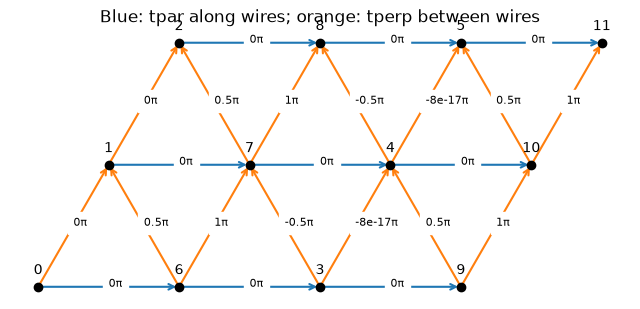

In [5]:
positions = xy[:,0,None]*a1 + xy[:,1,None]*a2
fig, ax = plt.subplots(figsize=(8,4))
for i,j,t,theta,family in bonds:
    delta = xy[j]-xy[i]
    if tuple(delta) not in [(1,0),(0,1),(-1,1)]:
        continue
    p,q = positions[i], positions[j]
    color = "tab:blue" if family == "parallel" else "tab:orange"
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="->",color=color,lw=1.5))
    phase_pi = np.angle(np.exp(1j*theta))/np.pi
    ax.text(*((p+q)/2), f"{phase_pi:.1g}π", fontsize=8, backgroundcolor="white")
ax.scatter(*positions.T, color="black", zorder=3)
for i,p in enumerate(positions):
    ax.text(*(p+[0,0.09]), str(i), ha="center")
ax.set(aspect="equal", title="Blue: tpar along wires; orange: tperp between wires")
ax.axis("off")
plt.show()

## A small complex variational wavefunction

The flux requires complex amplitudes. We keep a real CNN but use **complex128 pairing weights**; Quantax trains their real and imaginary components. This example uses one residual block and four CNN channels, with full pairing dimension $d=2N=24$. The magnetic unit cell avoids incorrectly imposing translation by one site along $x$ in this gauge.

`ParticleHop` conserves the two spin populations. `C0` bounds the Euclidean parameter update norm; it is not an energy tolerance. These deliberately small defaults are for teaching, not production accuracy.

In [6]:
model = qtx.model.MultiplicativePfBackflow.resconv(
    d=2*N, nblocks=1, channels=4, kernel_size=3,
    dtype=jnp.float32, pairing_dtype=jnp.complex128)
state = qtx.state.Variational(model, max_parallel=(64,16,64))
sampler = qtx.sampler.ParticleHop(
    state, nsamples=nsamples, thermal_steps=20*N, sweep_steps=4*N)
optimizer = qtx.optimizer.AdamSR(
    state, H, C0=C0, t0=1000000, T=1000,
    clip=5.0, clip_mode="median_mad", clip_scale_floor=1e-8)
print("Trainable real parameters:", state.nparams)

/tmp/quantax-multbackflow-publish/quantax/model/multiplicative_backflow.py:273: FermixFallbackWarning: fermix: device platform cpu (the kernels need a CUDA GPU) -- falling back to the generic XLA implementation (LU / Parlett-Reid in jax.numpy; same results and singular-safe gradients, but much slower).
  sign, logabs = fermix.slogpf(self.pairing_matrix(s))


Trainable real parameters: 2953


### Independent check of the local-energy convention

Before optimizing, we recompute the local energy on one sampled configuration using a small explicit fermionic hopping routine and wavefunction ratios. This checks the complex hopping conjugation, fermion signs, and onsite interaction against Quantax's operator implementation.

In [7]:
s0 = np.asarray(sampler.sweep(0).spins[0])
occupied = s0 > 0
proposals, matrix_elements = [], []
for spin in range(2):
    for src in range(N):
        for dst in range(N):
            a,b = spin*N+src, spin*N+dst
            if h[dst,src] == 0 or not occupied[a] or occupied[b]:
                continue
            new = s0.copy()
            new[a],new[b] = -1,1
            sign = (-1)**int(occupied[min(a,b)+1:max(a,b)].sum())
            proposals.append(new)
            # Outgoing element is H[new,s0]; local energy needs H[s0,new].
            matrix_elements.append(sign*h[src,dst])
psi0 = state(jnp.asarray(s0)[None,:])
psi_new = state(jnp.asarray(np.array(proposals)))
ratios = np.asarray(psi_new.sign/psi0.sign * jnp.exp(psi_new.logabs-psi0.logabs))
manual = U*np.sum(occupied[:N] & occupied[N:]) + np.dot(matrix_elements,ratios)
quantax_energy = complex(np.asarray(H.Oloc(state,jnp.asarray(s0)[None,:]))[0])
np.testing.assert_allclose(manual,quantax_energy,rtol=1e-9,atol=1e-9)
print("Explicit fermion local-energy check passed:", quantax_energy)

/tmp/quantax-multbackflow-publish/quantax/model/multiplicative_backflow.py:273: FermixFallbackWarning: fermix: device platform cpu (the kernels need a CUDA GPU) -- falling back to the generic XLA implementation (LU / Parlett-Reid in jax.numpy; same results and singular-safe gradients, but much slower).
  sign, logabs = fermix.slogpf(self.pairing_matrix(s))


Explicit fermion local-energy check passed: (20.86335301651383+1.0593561148010822j)


/tmp/quantax-multbackflow-publish/quantax/model/multiplicative_backflow.py:273: FermixFallbackWarning: fermix: device platform cpu (the kernels need a CUDA GPU) -- falling back to the generic XLA implementation (LU / Parlett-Reid in jax.numpy; same results and singular-safe gradients, but much slower).
  sign, logabs = fermix.slogpf(self.pairing_matrix(s))


step   1: E/N=+1.896364, Var(E)=62.7, |update|=0.1


step   2: E/N=+1.867309, Var(E)=41.8, |update|=0.1
step   3: E/N=+1.840829, Var(E)=37.2, |update|=0.1


step   5: E/N=+1.621951, Var(E)=34.1, |update|=0.1


step  10: E/N=+1.316967, Var(E)=21.3, |update|=0.1


step  15: E/N=+0.986422, Var(E)=30.1, |update|=0.1


step  20: E/N=+0.824277, Var(E)=24.3, |update|=0.1


step  25: E/N=+0.435139, Var(E)=34.3, |update|=0.1


step  30: E/N=+0.191563, Var(E)=19.4, |update|=0.1
Training elapsed: 24.8 s


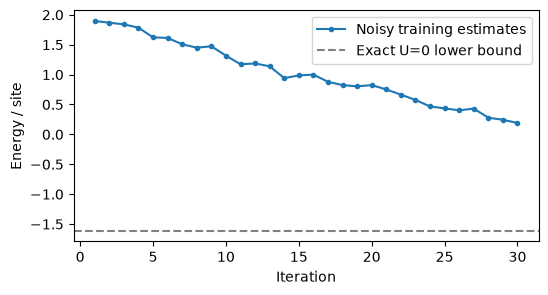

In [8]:
history = []
started = time.monotonic()
for step in range(nsteps):
    samples = sampler.sweep()
    update = optimizer.get_step(samples)
    energy = float(np.real(optimizer.energy))
    variance = float(optimizer.VarE)
    step_norm = float(jnp.linalg.norm(update))
    if not np.isfinite([energy,variance,step_norm]).all():
        raise FloatingPointError(f"Nonfinite update at step {step+1}")
    state.update(update)
    history.append((step+1, energy/N, variance, step_norm))
    if step < 3 or (step+1)%5 == 0:
        print(f"step {step+1:3d}: E/N={energy/N:+.6f}, Var(E)={variance:.3g}, |update|={step_norm:.3g}")
print(f"Training elapsed: {time.monotonic()-started:.1f} s")
fig, ax = plt.subplots(figsize=(6,3))
history = np.asarray(history)
ax.plot(history[:,0],history[:,1],".-",label="Noisy training estimates")
ax.axhline(E_free/N,color="gray",ls="--",label="Exact U=0 lower bound")
ax.set(xlabel="Iteration",ylabel="Energy / site")
ax.legend()
plt.show()

## Evaluate the final, frozen parameters

Training energies belong to changing wavefunctions. Now freeze the final parameters, rethermalize, and measure energy and double occupancy. Local energies can be complex even for a Hermitian Hamiltonian; the exact expectation is real. The imaginary block mean is a useful sampling diagnostic.

The error bars below are **naive standard errors across sequential sweep blocks**. They are not guaranteed to account for autocorrelation. Increase the number of samples, block separation, and evaluation blocks, and compare independent seeds before interpreting close energy differences.

In [9]:
sampler.sweep(20*N)
energy_blocks, doublon_blocks = [], []
for _ in range(n_eval_blocks):
    samples = sampler.sweep()
    energy_blocks.append(np.asarray(H.Oloc(state,samples)).mean()/N)
    doublon_blocks.append(np.asarray(D.Oloc(state,samples)).real.mean())
energy_blocks = np.asarray(energy_blocks)
doublon_blocks = np.asarray(doublon_blocks)
def block_sem(x):
    return np.std(x,ddof=1)/np.sqrt(len(x))
print(f"Frozen E/N = {energy_blocks.real.mean():+.6f} +/- {block_sem(energy_blocks.real):.6f} (naive block SEM)")
print(f"Imag E/N   = {energy_blocks.imag.mean():+.6f} +/- {block_sem(energy_blocks.imag):.6f}")
print(f"Double occupancy/site = {doublon_blocks.mean():.6f} +/- {block_sem(doublon_blocks):.6f}")

Frozen E/N = +0.105626 +/- 0.014281 (naive block SEM)
Imag E/N   = +0.000172 +/- 0.005985
Double occupancy/site = 0.022396 +/- 0.000821


## Suggested exercises

1. Set `tperp=0`, restart, and verify the decoupled-wire spectrum check. Flux through a triangle is not physically measurable when its interwire bonds have zero amplitude.
2. Compare `tperp/tpar = 0.25, 0.5, 1.0` at fixed `U/tpar`. Restart for each parameter set; changing Python variables does not rebuild an existing operator.
3. Compare U=7 and U=9. Raise `nsteps`, `nsamples`, and CNN width gradually, and check multiple seeds. Thirty updates and 64 chains will generally not converge this interacting model.
4. Reverse the sign of **all** Peierls phases and verify the triangle Wilson products become $-i$. Without other time-reversal-breaking terms, complex conjugation preserves the exact energy spectrum.
5. Use noninteracting diagonalization as an exact check at U=0. At half filling the interacting sector has $\binom{12}{6}^2=853{,}776$ states, so this notebook avoids full interacting exact diagonalization on a laptop.

A different boundary twist or a cylinder is a different finite-size Hamiltonian; modify boundary links explicitly and repeat the flux checks rather than simply deleting links from the periodic model.